# Video Game Market Analysis

## Business Context

Ice is an online video game retailer operating across multiple international markets. The company wants to identify patterns associated with commercially successful video games in order to support product selection and advertising decisions for the upcoming year.

This analysis uses historical video game sales data through 2016, including platform, genre, regional sales, critic scores, user scores, and ESRB ratings.

## Objective

The objective of this project is to identify the factors associated with video game sales performance and evaluate how these patterns vary across platforms, genres, and geographic markets.

The analysis focuses on:

* Preparing and validating the dataset.
* Exploring video game release and sales trends.
* Identifying potentially relevant platforms and genres.
* Examining the relationship between reviews and sales.
* Comparing consumer preferences across North America, Europe, and Japan.
* Testing statistical hypotheses about user ratings.
* Translating the findings into business-oriented recommendations.

## Analytical Workflow

1. Data loading and initial exploration
2. Data cleaning and preprocessing
3. Exploratory data analysis
4. Platform and genre analysis
5. Regional market analysis
6. Statistical hypothesis testing
7. Conclusions and business recommendations

## 1. Data Loading and Initial Exploration

In [1]:
# Import the libraries used in the analysis
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline
from scipy import stats as st

In [2]:
# Load the dataset
df_data = pd.read_csv('../data/games.csv')

In [3]:
# Display a sample of the data
df_data.sample(5)

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
12099,Pizza Delivery Boy,Wii,2010.0,Simulation,0.06,0.00,0.00,0.00,NaN,tbd,E
5832,Monsters vs. Aliens,PS3,2009.0,Action,0.21,0.05,0.00,0.04,66.0,4.5,E10+
770,R.C. Pro-Am,NES,1988.0,Racing,1.47,0.38,0.19,0.10,NaN,NaN,NaN
11506,Looney Tunes: Acme Arsenal,X360,2007.0,Action,0.06,0.01,0.00,0.01,40.0,6.8,E10+
9777,Lovely Lisa,DS,2007.0,Simulation,0.11,0.00,0.00,0.01,NaN,tbd,E


In [4]:
# Review the general structure and data types
df_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


In [5]:
# Count missing values in each column
df_data.isna().sum()

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

In [6]:
# Review descriptive statistics for numerical columns
df_data.describe()

,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


In [7]:
# Check for duplicated rows
print('Duplicated rows:', df_data.duplicated().sum())

Duplicated rows: 0


### Initial Observations

The dataset contains information on video game releases, platforms, genres, regional sales, review scores, and ESRB ratings.

The initial review shows missing values in `Year_of_Release`, `Critic_Score`, `User_Score`, and `Rating`. The `User_Score` column is stored as text because it includes values such as `tbd` ("to be determined"), so it must be converted before statistical analysis.

## 2. Data Preparation

In [8]:
# Convert column names to lowercase
col_names_lower = []

for old_name in df_data.columns:
    name_lowered = old_name.lower()
    col_names_lower.append(name_lowered)

df_data.columns = col_names_lower
print(df_data.columns)

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='str')


In [9]:
# Convert user scores to numeric values.
# Values such as 'tbd' are converted to NaN because they are not actual scores.
df_data['user_score'] = pd.to_numeric(df_data['user_score'], errors='coerce')

# Remove the very few rows without a game name or genre.
df_data = df_data.dropna(subset=['name', 'genre'])

# Replace missing ESRB ratings with a clear category.
df_data['rating'] = df_data['rating'].fillna('Unknown')

df_data.isna().sum()

name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating                0
dtype: int64

### Missing-Value Decisions

- `user_score`: values such as `tbd` were converted to `NaN` because they do not represent a numerical rating.
- `critic_score` and `user_score`: missing scores were kept as missing values instead of replacing them with zero. A missing review is not the same as a score of zero.
- `year_of_release`: missing years were not replaced because assigning an artificial year could distort the historical analysis.
- `rating`: missing ESRB values were labeled as `Unknown` so they remain visible in the regional analysis.
- Rows without a game name or genre were removed because those fields are essential for this project.

In [10]:
# Calculate total sales for each game
df_data['total_sales'] = (
    df_data['na_sales']
    + df_data['eu_sales']
    + df_data['jp_sales']
    + df_data['other_sales']
)

df_data[['name', 'platform', 'genre', 'total_sales']].head()

,name,platform,genre,total_sales
0,Wii Sports,Wii,Sports,82.54
1,Super Mario Bros.,NES,Platform,40.24
2,Mario Kart Wii,Wii,Racing,35.52
3,Wii Sports Resort,Wii,Sports,32.77
4,Pokemon Red/Pokemon Blue,GB,Role-Playing,31.38


## 3. Exploratory Data Analysis

### 3.1 Games Released by Year

year_of_release
1980.0       9
1981.0      46
1982.0      36
1983.0      17
1984.0      14
1985.0      14
1986.0      21
1987.0      16
1988.0      15
1989.0      17
1990.0      16
1991.0      41
1992.0      43
1993.0      60
1994.0     121
1995.0     219
1996.0     263
1997.0     289
1998.0     379
1999.0     338
2000.0     350
2001.0     482
2002.0     829
2003.0     775
2004.0     762
2005.0     939
2006.0    1006
2007.0    1197
2008.0    1427
2009.0    1426
2010.0    1255
2011.0    1136
2012.0     653
2013.0     544
2014.0     581
2015.0     606
2016.0     502
Name: count, dtype: int64


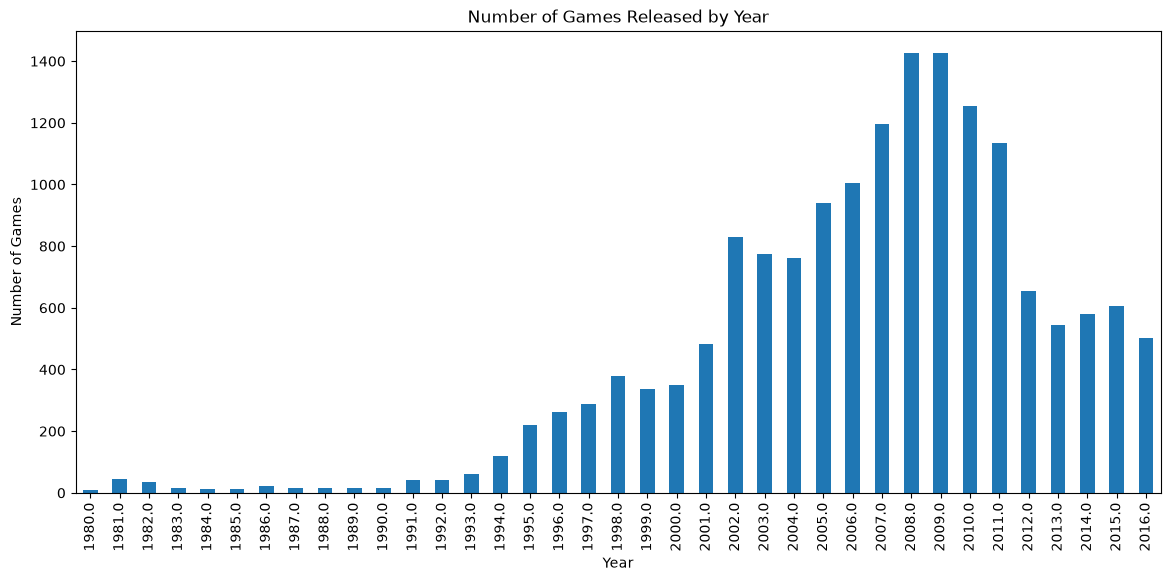

In [11]:
# Count the number of games released each year
games_per_year = df_data['year_of_release'].value_counts().sort_index()
print(games_per_year)

# Plot the number of releases by year
games_per_year.plot(kind='bar', figsize=(14, 6))
plt.title('Number of Games Released by Year')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.show()

The number of releases is relatively low in the earliest years of the dataset and grows strongly from the 1990s onward. Because the business objective is to support decisions for 2017, very old releases are useful for understanding long-term market cycles, but they are less representative of the current market.

### 3.2 Historical Platform Sales

In [12]:
# Calculate total sales by platform for the full dataset
platform_sales = (
    df_data.groupby('platform')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

print(platform_sales.head(10))

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: total_sales, dtype: float64


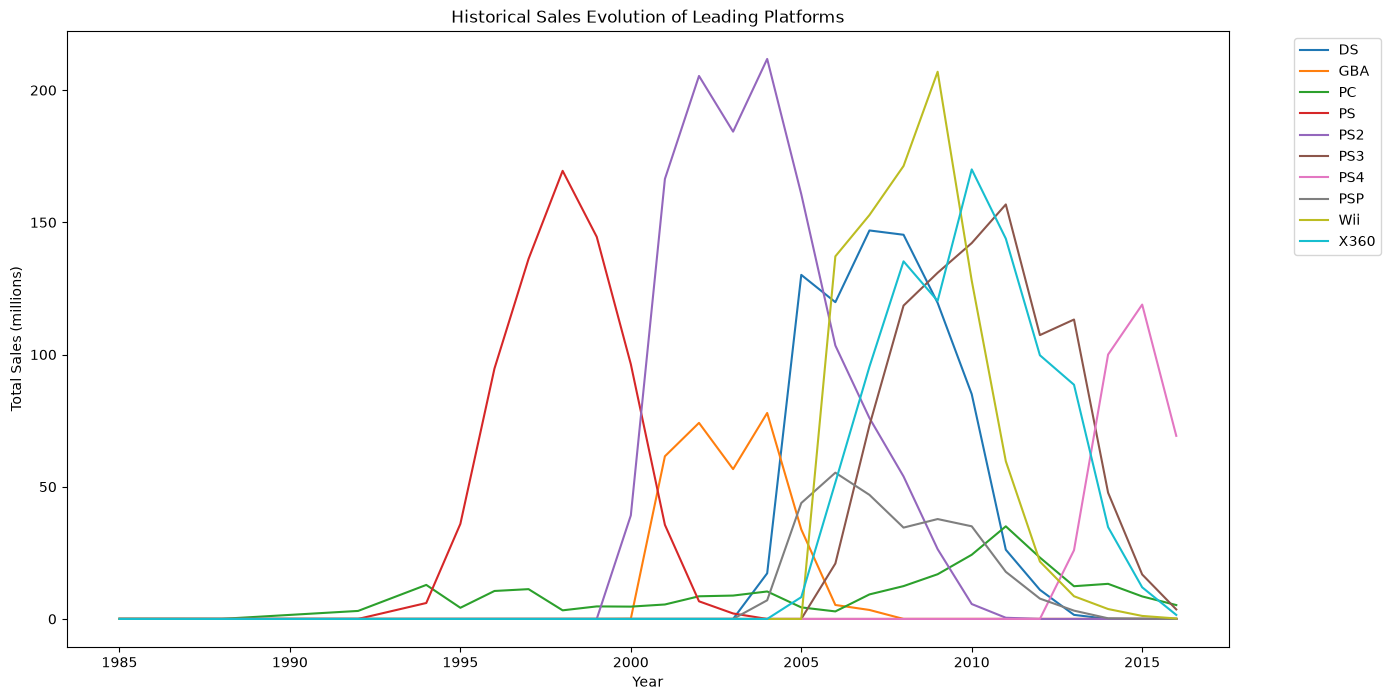

In [13]:
# Analyze annual sales for the historically strongest platforms
top_platforms = platform_sales.head(10)
top_platform_names = top_platforms.index.tolist()

platform_year_sales = (
    df_data[df_data['platform'].isin(top_platform_names)]
    .groupby(['platform', 'year_of_release'])['total_sales']
    .sum()
    .unstack(fill_value=0)
)

platform_year_sales.T.plot(figsize=(15, 8))
plt.title('Historical Sales Evolution of Leading Platforms')
plt.xlabel('Year')
plt.ylabel('Total Sales (millions)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

The chart shows that platforms have clear life cycles: sales rise after a platform enters the market, reach a peak, and later decline as newer generations become more important.

For the 2017 business decision, the analysis should therefore focus on the most recent years rather than giving the same weight to platforms that are no longer active.

### 3.3 Relevant Market Period: 2012–2016

In [14]:
# Keep the most recent period for the 2017 market analysis
recent_data = df_data[
    (df_data['year_of_release'] >= 2012)
    & (df_data['year_of_release'] <= 2016)
]

print('Games in the 2012-2016 period:', recent_data.shape[0])

Games in the 2012-2016 period: 2886


In [15]:
# Calculate recent sales by platform
recent_platform_sales = (
    recent_data.groupby('platform')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

print(recent_platform_sales.head(10))

platform
PS4     314.14
PS3     288.79
X360    236.54
3DS     194.61
XOne    159.32
WiiU     82.19
PC       62.65
PSV      49.18
Wii      35.37
DS       12.55
Name: total_sales, dtype: float64


For 2012–2016, PS4 has the highest total sales, followed by PS3, Xbox 360, Nintendo 3DS, and Xbox One. However, some of the older platforms in this ranking are already declining, so recent direction is also important when planning for 2017.

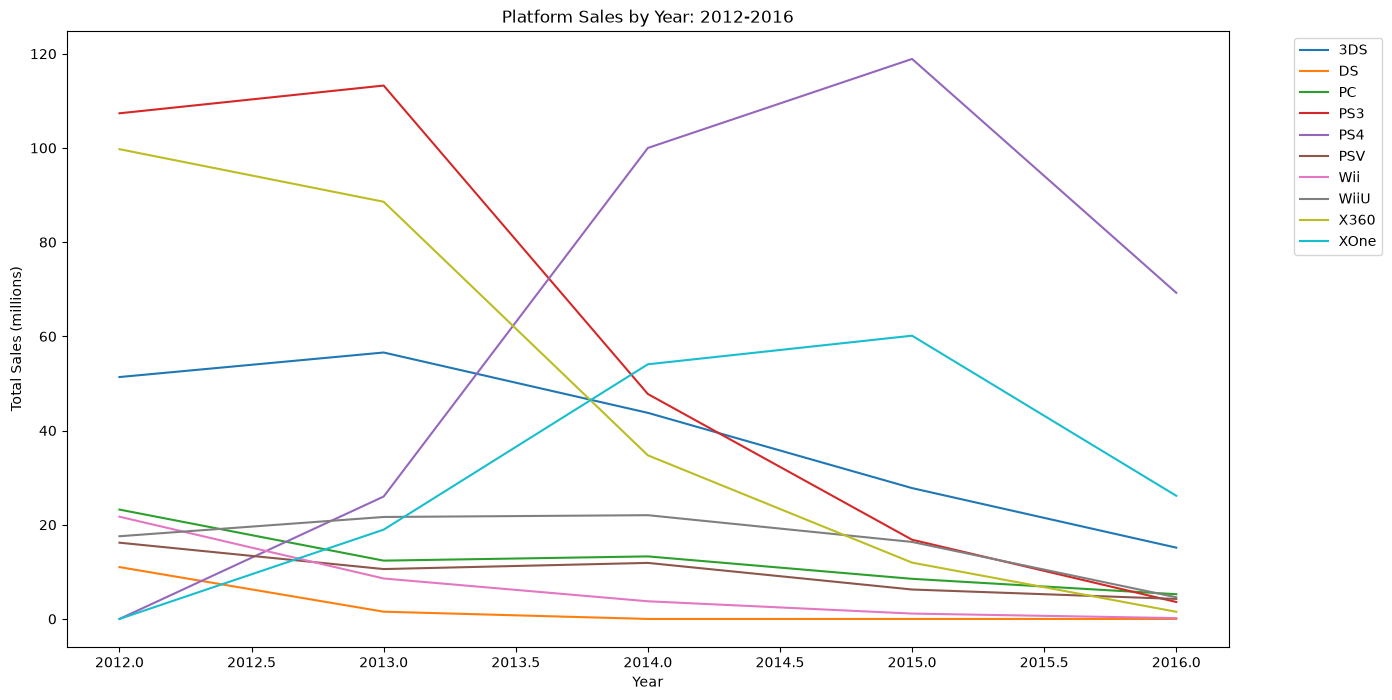

In [16]:
# Compare recent platform performance by year
recent_top_platforms = recent_platform_sales.head(10).index.tolist()

recent_platform_year_sales = (
    recent_data[recent_data['platform'].isin(recent_top_platforms)]
    .groupby(['platform', 'year_of_release'])['total_sales']
    .sum()
    .unstack(fill_value=0)
)

recent_platform_year_sales.T.plot(figsize=(15, 8))
plt.title('Platform Sales by Year: 2012-2016')
plt.xlabel('Year')
plt.ylabel('Total Sales (millions)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### 3.4 Distribution of Sales by Platform

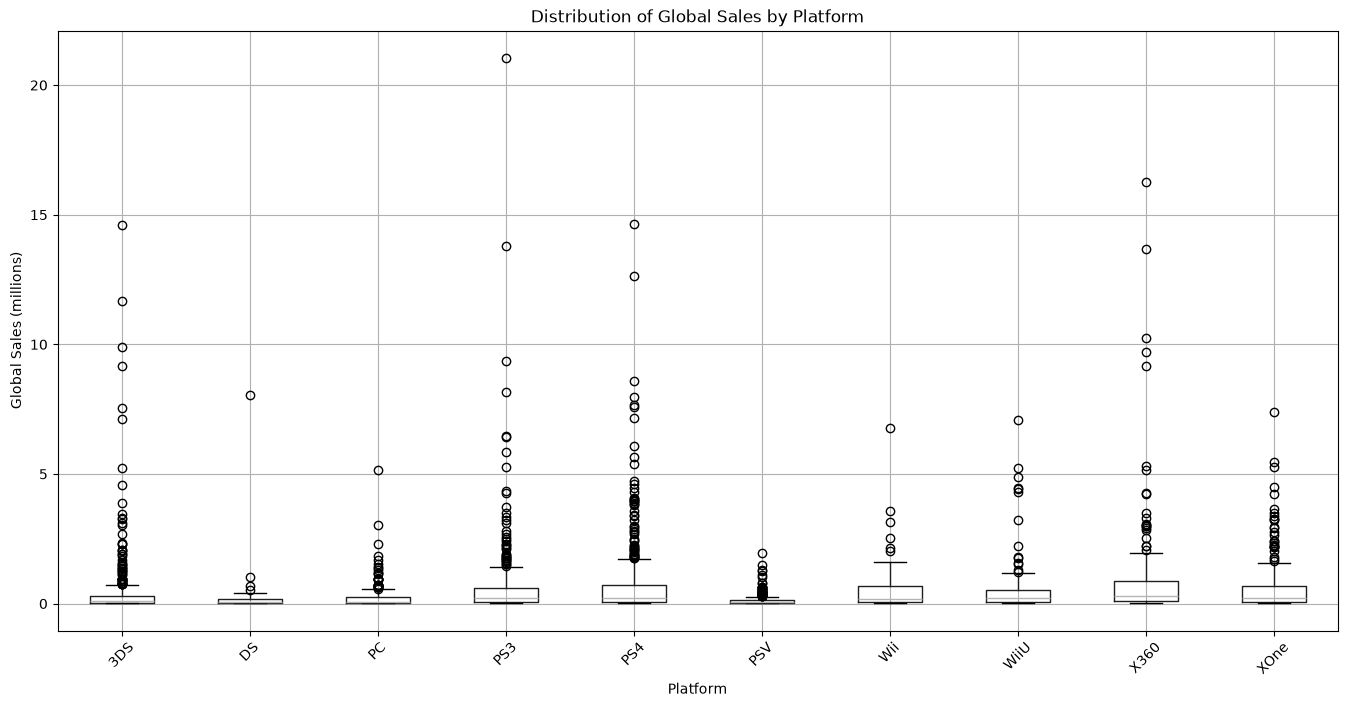

In [17]:
# Use the leading recent platforms for a readable boxplot
top_platforms_list = recent_platform_sales.head(10).index.tolist()

df_top_platforms = recent_data[
    recent_data['platform'].isin(top_platforms_list)
]

df_top_platforms.boxplot(
    column='total_sales',
    by='platform',
    figsize=(16, 8)
)

plt.title('Distribution of Global Sales by Platform')
plt.suptitle('')
plt.xlabel('Platform')
plt.ylabel('Global Sales (millions)')
plt.xticks(rotation=45)
plt.show()

In [18]:
# Descriptive statistics by platform
print(
    df_top_platforms.groupby('platform')['total_sales'].describe()
)

          count      mean       std   min     25%   50%     75%    max
platform                                                              
3DS       396.0  0.491439  1.387161  0.01  0.0400  0.11  0.3125  14.60
DS         31.0  0.404839  1.439245  0.01  0.0200  0.05  0.1850   8.06
PC        250.0  0.250600  0.494640  0.01  0.0300  0.08  0.2400   5.14
PS3       493.0  0.585781  1.462855  0.01  0.0500  0.20  0.6100  21.05
PS4       392.0  0.801378  1.609456  0.01  0.0600  0.20  0.7300  14.63
PSV       411.0  0.119659  0.203011  0.01  0.0200  0.05  0.1200   1.96
Wii        54.0  0.655000  1.165447  0.01  0.0625  0.18  0.6875   6.76
WiiU      147.0  0.559116  1.058836  0.01  0.0800  0.22  0.5250   7.09
X360      292.0  0.810068  1.712069  0.01  0.1000  0.31  0.8700  16.27
XOne      247.0  0.645020  1.036139  0.01  0.0600  0.22  0.6850   7.39


Sales distributions are strongly affected by a small number of very successful titles. Most games sell much less than the biggest outliers, so average sales alone do not describe the full distribution.

This also shows why a platform with several blockbuster games can produce much higher total sales even when many individual titles have modest performance.

### 3.5 Review Scores and PS4 Sales

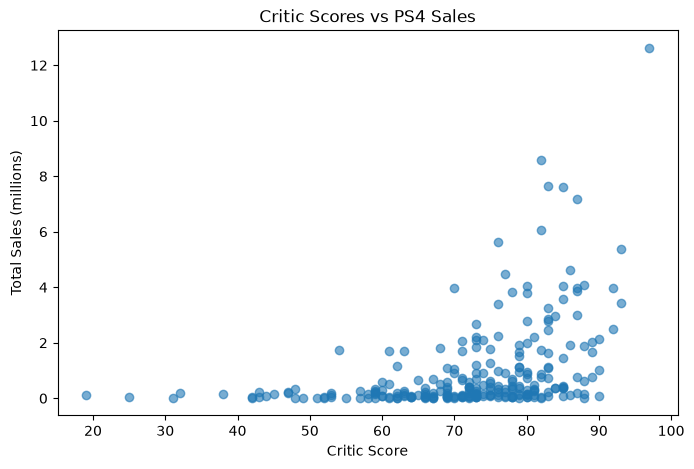

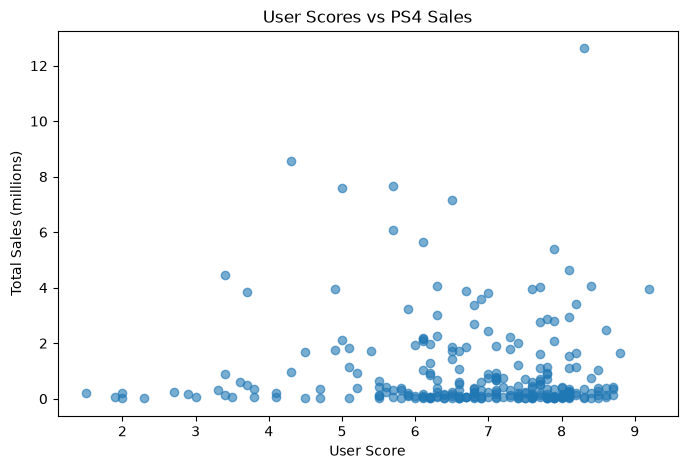

In [19]:
# Keep PS4 games with available review scores
ps4_data = recent_data[recent_data['platform'] == 'PS4']

ps4_critic = ps4_data.dropna(subset=['critic_score'])
ps4_user = ps4_data.dropna(subset=['user_score'])

# Critic Score vs Sales
plt.figure(figsize=(8, 5))
plt.scatter(ps4_critic['critic_score'], ps4_critic['total_sales'], alpha=0.6)
plt.xlabel('Critic Score')
plt.ylabel('Total Sales (millions)')
plt.title('Critic Scores vs PS4 Sales')
plt.show()

# User Score vs Sales
plt.figure(figsize=(8, 5))
plt.scatter(ps4_user['user_score'], ps4_user['total_sales'], alpha=0.6)
plt.xlabel('User Score')
plt.ylabel('Total Sales (millions)')
plt.title('User Scores vs PS4 Sales')
plt.show()

In [20]:
# Calculate correlations
corr_critic = ps4_critic['critic_score'].corr(ps4_critic['total_sales'])
corr_user = ps4_user['user_score'].corr(ps4_user['total_sales'])

print(f'Critic score correlation with sales: {corr_critic:.3f}')
print(f'User score correlation with sales: {corr_user:.3f}')

Critic score correlation with sales: 0.407
User score correlation with sales: -0.032


For PS4, critic scores have a moderate positive correlation with sales, while user scores show almost no linear correlation with sales.

This means critic scores are more strongly associated with sales in this specific case. However, correlation does not mean that critic reviews directly cause higher sales.

### 3.6 Comparing the Same Game Across Platforms

In [21]:
# Compare Grand Theft Auto V across platforms
gta_v_data = df_data[
    df_data['name'].str.contains('Grand Theft Auto V', na=False)
]

print(
    gta_v_data[
        ['name', 'platform', 'total_sales', 'critic_score', 'user_score']
    ].sort_values('total_sales', ascending=False)
)

                                                   name platform  total_sales  \
16                                   Grand Theft Auto V      PS3        21.05   
23                                   Grand Theft Auto V     X360        16.27   
42                                   Grand Theft Auto V      PS4        12.62   
165                                  Grand Theft Auto V     XOne         5.47   
620   Rockstar Games Double Pack: Grand Theft Auto I...       XB         2.49   
1034  Rockstar Games Double Pack: Grand Theft Auto I...      PS2         1.73   
1730                                 Grand Theft Auto V       PC         1.17   

      critic_score  user_score  
16            97.0         8.2  
23            97.0         8.1  
42            97.0         8.3  
165           97.0         7.9  
620            NaN         NaN  
1034           NaN         NaN  
1730          96.0         7.9  


The same title can produce very different sales depending on the platform. This supports the idea that commercial performance depends on several factors rather than on the game title alone.

### 3.7 Genre Analysis

In [22]:
# Calculate recent sales by genre
genre_sales = (
    recent_data.groupby('genre')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

print(genre_sales)

genre
Action          441.12
Shooter         304.73
Role-Playing    192.80
Sports          181.07
Misc             85.04
Platform         61.00
Racing           53.50
Fighting         44.49
Simulation       35.12
Adventure        29.43
Strategy         13.34
Puzzle            4.89
Name: total_sales, dtype: float64


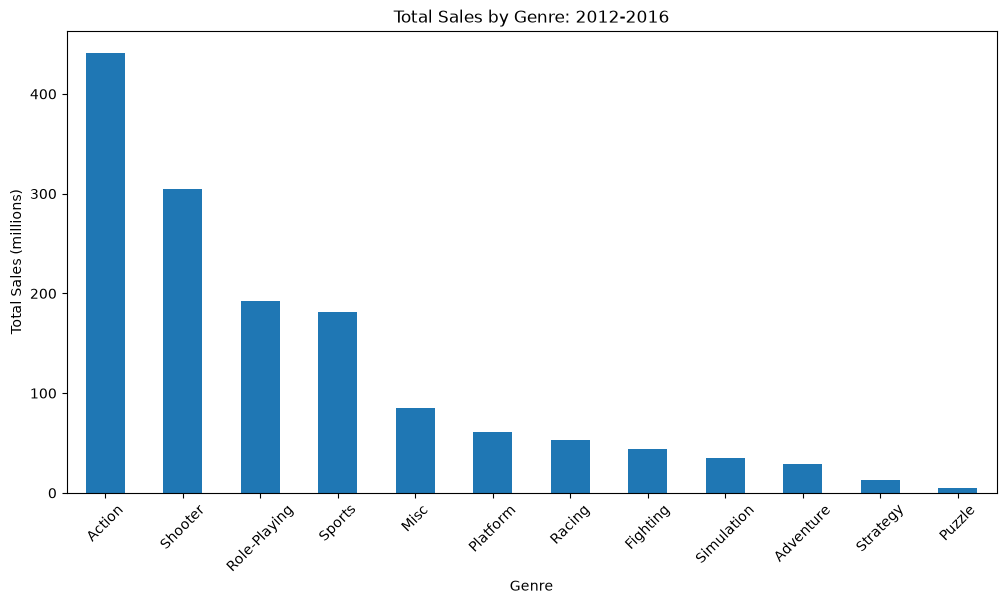

In [23]:
# Plot recent genre sales
genre_sales.plot(kind='bar', figsize=(12, 6))
plt.title('Total Sales by Genre: 2012-2016')
plt.xlabel('Genre')
plt.ylabel('Total Sales (millions)')
plt.xticks(rotation=45)
plt.show()

Action has the highest total sales during 2012–2016, followed by Shooter, Role-Playing, and Sports. These results suggest that Action and Shooter games are especially relevant for a broad commercial strategy, while Role-Playing becomes particularly important when regional differences are considered.

## 4. Regional Market Analysis

### 4.1 Leading Platforms by Region

In [24]:
# Top five platforms in each region during 2012-2016
na_platforms = (
    recent_data.groupby('platform')['na_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

eu_platforms = (
    recent_data.groupby('platform')['eu_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

jp_platforms = (
    recent_data.groupby('platform')['jp_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print('North America')
print(na_platforms)

print('\nEurope')
print(eu_platforms)

print('\nJapan')
print(jp_platforms)

North America
platform
X360    140.05
PS4     108.74
PS3     103.38
XOne     93.12
3DS      55.31
Name: na_sales, dtype: float64

Europe
platform
PS4     141.09
PS3     106.86
X360     74.52
XOne     51.59
3DS      42.64
Name: eu_sales, dtype: float64

Japan
platform
3DS     87.79
PS3     35.29
PSV     21.04
PS4     15.96
WiiU    13.01
Name: jp_sales, dtype: float64


North America and Europe share several leading platforms, although Xbox 360 is stronger in North America while PS4 leads Europe. Japan is clearly different: Nintendo 3DS has the highest sales, followed by Japanese-oriented platforms such as PS3 and PS Vita.

### 4.2 Leading Genres by Region

In [25]:
# Top five genres in each region
na_genre = (
    recent_data.groupby('genre')['na_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

eu_genre = (
    recent_data.groupby('genre')['eu_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

jp_genre = (
    recent_data.groupby('genre')['jp_sales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print('North America')
print(na_genre)

print('\nEurope')
print(eu_genre)

print('\nJapan')
print(jp_genre)

North America
genre
Action          177.84
Shooter         144.77
Sports           81.53
Role-Playing     64.00
Misc             38.19
Name: na_sales, dtype: float64

Europe
genre
Action          159.34
Shooter         113.47
Sports           69.09
Role-Playing     48.53
Racing           27.29
Name: eu_sales, dtype: float64

Japan
genre
Role-Playing    65.44
Action          52.80
Misc            12.86
Simulation      10.41
Fighting         9.44
Name: jp_sales, dtype: float64


North America and Europe show similar preferences: Action and Shooter are the two strongest genres. Japan behaves differently, with Role-Playing as the leading genre. This difference is important when adapting product and advertising decisions by market.

### 4.3 ESRB Ratings by Region

In [26]:
# Sales by ESRB rating in each region
na_rating = (
    recent_data.groupby('rating')['na_sales']
    .sum()
    .sort_values(ascending=False)
)

eu_rating = (
    recent_data.groupby('rating')['eu_sales']
    .sum()
    .sort_values(ascending=False)
)

jp_rating = (
    recent_data.groupby('rating')['jp_sales']
    .sum()
    .sort_values(ascending=False)
)

print('North America')
print(na_rating)

print('\nEurope')
print(eu_rating)

print('\nJapan')
print(jp_rating)

North America
rating
M          231.57
E          114.37
Unknown    103.31
E10+        75.70
T           66.02
Name: na_sales, dtype: float64

Europe
rating
M          193.96
E          113.03
Unknown     91.50
E10+        55.37
T           52.96
Name: eu_sales, dtype: float64

Japan
rating
Unknown    108.84
E           28.33
T           26.02
M           21.20
E10+         8.19
Name: jp_sales, dtype: float64


M-rated games lead sales in North America and Europe during the selected period. Japan shows a different pattern, and a large share of Japanese sales belongs to games with an `Unknown` ESRB rating. Therefore, ESRB comparisons in Japan should be interpreted carefully because many observations do not have a recorded rating.

## 5. Statistical Hypothesis Testing

### 5.1 Xbox One vs PC User Ratings

**Null hypothesis (H₀):** The average user ratings for Xbox One and PC are equal.

**Alternative hypothesis (H₁):** The average user ratings for Xbox One and PC are different.

A significance level of 5% (`alpha = 0.05`) is used.

In [27]:
# Prepare the samples using games with available user scores
xone_scores = recent_data[
    recent_data['platform'] == 'XOne'
]['user_score'].dropna()

pc_scores = recent_data[
    recent_data['platform'] == 'PC'
]['user_score'].dropna()

print('Xbox One observations:', len(xone_scores))
print('PC observations:', len(pc_scores))
print('Xbox One mean:', xone_scores.mean())
print('PC mean:', pc_scores.mean())
print('Xbox One variance:', xone_scores.var())
print('PC variance:', pc_scores.var())

Xbox One observations: 182
PC observations: 206
Xbox One mean: 6.521428571428572
PC mean: 6.4286407766990274
Xbox One variance: 1.9069968429360695
PC variance: 2.770443997158418


In [28]:
alpha = 0.05

# Use Welch's t-test because the sample variances are not identical
results_platforms = st.ttest_ind(
    xone_scores,
    pc_scores,
    equal_var=False
)

print('p-value:', results_platforms.pvalue)

if results_platforms.pvalue < alpha:
    print('We reject the null hypothesis.')
else:
    print('We cannot reject the null hypothesis.')

p-value: 0.5489537965134912
We cannot reject the null hypothesis.


The p-value is greater than 0.05, so the null hypothesis cannot be rejected. The data do not provide sufficient statistical evidence to conclude that the average user ratings for Xbox One and PC are different.

### 5.2 Action vs Sports User Ratings

**Null hypothesis (H₀):** The average user ratings for Action and Sports games are equal.

**Alternative hypothesis (H₁):** The average user ratings for Action and Sports games are different.

The same 5% significance level is used.

In [29]:
# Prepare the genre samples
action_scores = recent_data[
    recent_data['genre'] == 'Action'
]['user_score'].dropna()

sports_scores = recent_data[
    recent_data['genre'] == 'Sports'
]['user_score'].dropna()

print('Action observations:', len(action_scores))
print('Sports observations:', len(sports_scores))
print('Action mean:', action_scores.mean())
print('Sports mean:', sports_scores.mean())
print('Action variance:', action_scores.var())
print('Sports variance:', sports_scores.var())

Action observations: 523
Sports observations: 195
Action mean: 6.825047801147227
Sports mean: 5.455897435897437
Action variance: 1.8890840494348111
Sports variance: 3.022890298704732


In [30]:
alpha = 0.05

results_genre = st.ttest_ind(
    action_scores,
    sports_scores,
    equal_var=False
)

print('p-value:', results_genre.pvalue)

if results_genre.pvalue < alpha:
    print('We reject the null hypothesis.')
else:
    print('We cannot reject the null hypothesis.')

p-value: 4.243077765726399e-20
We reject the null hypothesis.


The p-value is far below 0.05, so the null hypothesis is rejected. The data provide statistical evidence that the average user ratings for Action and Sports games are different.

### Statistical Criterion

The significance level was set at 5%. If the p-value is below 0.05, the null hypothesis is rejected. If the p-value is greater than or equal to 0.05, there is not enough evidence to reject the null hypothesis.

A statistical test does not prove that a hypothesis is true; it indicates whether the observed data provide enough evidence to reject the null hypothesis.

## 6. Conclusions and Business Recommendations

This project analyzed historical video game data to identify patterns that could support Ice's commercial planning for 2017.

### Main Findings

- Platform sales follow clear life cycles, so recent market behavior is more useful for short-term planning than very old historical performance.
- For 2012–2016, PS4 has the highest total sales, while Xbox One and Nintendo 3DS also remain commercially relevant.
- Action is the leading genre in total recent sales, followed by Shooter, Role-Playing, and Sports.
- North America and Europe have relatively similar preferences, while Japan has a distinct market profile. Nintendo 3DS and Role-Playing games are especially important in Japan.
- For PS4, critic scores have a moderate positive association with sales, while user scores have almost no linear relationship with sales.
- There is not enough evidence to conclude that Xbox One and PC have different average user ratings.
- Action and Sports games show a statistically significant difference in average user ratings.

### Business Interpretation

For a 2017 campaign, PS4 should receive strong attention because of its recent sales performance. Action and Shooter are attractive genres for broad campaigns, but the strategy should be adapted by region.

Japan should not be treated as a smaller version of the North American or European market. Its stronger preference for Nintendo 3DS and Role-Playing games suggests that regional product selection and advertising should be adjusted accordingly.

Finally, commercial success should not be evaluated using a single variable. Platform, genre, region, reviews, and rating information should be considered together when identifying promising games.